# 쓰레기 12종 분류 — 실험 결과와 최종 모델 (E1~E9)

- 모델: ImageNet ResNet18 (torchvision), PyTorch만 사용
- 최종 모델 **E9**: layer4 + MLP 헤드(512→256→128→12, ReLU) 학습, 나머지 백본 동결, 입력 224px, degrade 증강(어둡게·흐림)
- 학습 데이터 train_mix 12,000장(클래스당 1,000), 고정 분할, 한 번에 한 변수 변경, 최종 TEST 1회
- 이 노트북은 저장된 결과 파일만 읽는다 (재학습·TEST 재평가 없음). 학습 코드는 `gc_lib.py`, `run_exp.py`, `overnight*.py`

In [1]:
import json, inspect
import pandas as pd
from IPython.display import Image, display
import gc_lib as G
pd.set_option('display.width', 200)

## 1. 최종 모델 구조와 학습 설정

In [2]:
cfg = json.load(open(G.HISTORY / 'E9_cfg.json', encoding='utf-8'))
print(json.dumps(cfg, ensure_ascii=False, indent=1))
print(G.model_from_cfg(cfg).fc)

{
 "seed": 42,
 "model": "resnet18",
 "img_size": 224,
 "freeze": "layer4",
 "optimizer": "adamw",
 "lr": 0.001,
 "weight_decay": 0.0001,
 "batch": 32,
 "epochs": 10,
 "patience": 3,
 "aug": [
  "degrade"
 ],
 "train_data": "mix",
 "max_per_class": 1000,
 "threads": 12,
 "num_workers": 0,
 "exp_id": "E9",
 "base_exp": "E8",
 "changed_var": "img_size",
 "value": "224",
 "notes": "E8 + 입력 224px (선택 기준 (val+val_ext)/2, val_hard 참고)",
 "hidden": [
  256,
  128
 ],
 "act": "relu"
}
Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=12, bias=True)
)


In [3]:
print(inspect.getsource(G.build_head))
print(inspect.getsource(G.build_transforms))

def build_head(in_f: int, hidden=(), act: str = "relu", dropout: float = 0.0) -> nn.Module:
    """분류 헤드. hidden=() → Linear 하나(기존과 동일). hidden=(256,) → 512→256→12, (256,128) → 512→256→128→12."""
    if not hidden:
        return nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, len(CLASSES))) if dropout > 0 \
            else nn.Linear(in_f, len(CLASSES))
    layers, d = [], in_f
    for h in hidden:
        layers += [nn.Linear(d, h), ACTS[act]()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, len(CLASSES)))
    return nn.Sequential(*layers)

def build_transforms(img_size: int, aug: list[str] | tuple = ()):
    """aug 이름: hflip, rotate, rrc, color, blur, degrade. 빈 목록이면 Resize+Normalize만."""
    aug = list(aug)
    tf = []
    if "rrc" in aug:
        tf.append(transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)))
    else:
        tf.append(transforms.Resize((img_size, img_size)))
    if "hflip" in aug:
      

## 2. 전체 실험 비교 (TEST는 E9 한 번만 사용)
선택 기준: S3 = (val + val_ext + val_hard)/3, +1%p 이상 & clothes·shoes val −3%p 이내일 때 채택. E9(224px)는 val_hard가 160px로 고정 생성돼 (val+val_ext)/2로 판정(사전 등록).

In [4]:
exp = pd.read_csv(G.EXP_CSV)
exp['val_hard'] = [json.load(open(G.HISTORY / f'{e}_val_hard.json', encoding='utf-8'))['val_hard_acc'] for e in exp.exp_id]
exp['S3'] = ((exp.val_acc + exp.val_ext_acc + exp.val_hard) / 3).round(4)
exp[['exp_id','base_exp','changed_var','value','img_size','freeze','aug','train_acc','val_acc','val_ext_acc','val_hard','S3','best_epoch','epochs_run','time_min','test_acc','test_used']]

,exp_id,base_exp,changed_var,value,img_size,freeze,aug,train_acc,val_acc,val_ext_acc,val_hard,S3,best_epoch,epochs_run,time_min,test_acc,test_used
0,E1,NaN,baseline,kaggle<=1000/cls,160,backbone,none,0.9423,0.9317,0.388,0.6133,0.6443,6,9,36.6,NaN,0
1,E2,E1,train_data,mix(train_mix.csv),160,backbone,none,0.8364,0.8956,0.724,0.6892,0.7696,3,6,33.2,NaN,0
2,E3,E2,aug,degrade,160,backbone,degrade,0.8362,0.8930,0.744,0.7150,0.7840,5,8,43.0,NaN,0
3,E4,E3,hidden,"1층(512→256, ReLU)",160,backbone,degrade,0.8952,0.9115,0.784,0.7633,0.8196,6,9,34.8,NaN,0
4,E5,E3,hidden,"2층(512→256→128, ReLU)",160,backbone,degrade,0.9119,0.9085,0.820,0.7683,0.8323,8,10,37.7,NaN,0
5,E6,E5,act,gelu,160,backbone,degrade,0.9158,0.9162,0.790,0.7617,0.8226,7,10,37.7,NaN,0
6,E7,E5,aug,degrade_strong(밝기 0.15~1.0),160,backbone,degrade_strong,0.9046,0.9141,0.796,0.7667,0.8256,8,10,37.9,NaN,0
7,E8,E5,freeze,layer4,160,layer4,degrade,0.9488,0.9269,0.854,0.8292,0.8700,6,9,43.6,NaN,0
8,E9,E8,img_size,224,224,layer4,degrade,0.9713,0.9493,0.890,0.8342,0.8912,10,10,73.5,0.9394,1


## 3. 어려운 사진(val_hard, 1,200장) 손상별·출처별 정확도

In [5]:
rows = {}
for e in exp.exp_id:
    j = json.load(open(G.HISTORY / f'{e}_val_hard.json', encoding='utf-8'))
    rows[e] = {**{k: v['acc'] for k, v in j['by_corruption'].items()}, **{'src_' + k: v['acc'] for k, v in j['by_source'].items()}}
pd.DataFrame(rows).T

,blur,dark,glare,src_aihub,src_kaggle,src_realwaste
E1,0.5797,0.5931,0.6675,0.3556,0.8014,0.3455
E2,0.5646,0.7010,0.8010,0.6267,0.7686,0.5382
E3,0.6582,0.6912,0.7960,0.6667,0.7900,0.5636
E4,0.7190,0.7353,0.8363,0.7511,0.8143,0.6436
E5,0.7190,0.7377,0.8489,0.7822,0.8086,0.6545
E6,0.7038,0.7426,0.8388,0.7822,0.8186,0.6000
E7,0.7038,0.7475,0.8489,0.7600,0.8157,0.6473
E8,0.7924,0.8235,0.8715,0.8444,0.8643,0.7273
E9,0.7797,0.8284,0.8942,0.8356,0.8686,0.7455


## 4. 클래스별 val 정확도 (Kaggle val)

In [6]:
pd.concat({e: pd.read_csv(G.HISTORY / f'{e}_val_per_class.csv', index_col=0)['acc'] for e in ['E3','E5','E8','E9']}, axis=1).round(3)

,E3,E5,E8,E9
battery,0.852,0.965,0.958,0.979
biological,0.993,0.986,0.939,0.993
brown-glass,0.802,0.835,0.879,0.967
cardboard,0.872,0.850,0.880,0.902
clothes,0.951,0.946,0.982,0.981
green-glass,0.968,0.958,0.989,0.958
metal,0.750,0.776,0.802,0.905
paper,0.847,0.898,0.911,0.936
plastic,0.760,0.682,0.760,0.806
shoes,0.939,0.936,0.926,0.959


## 5. 학습 곡선

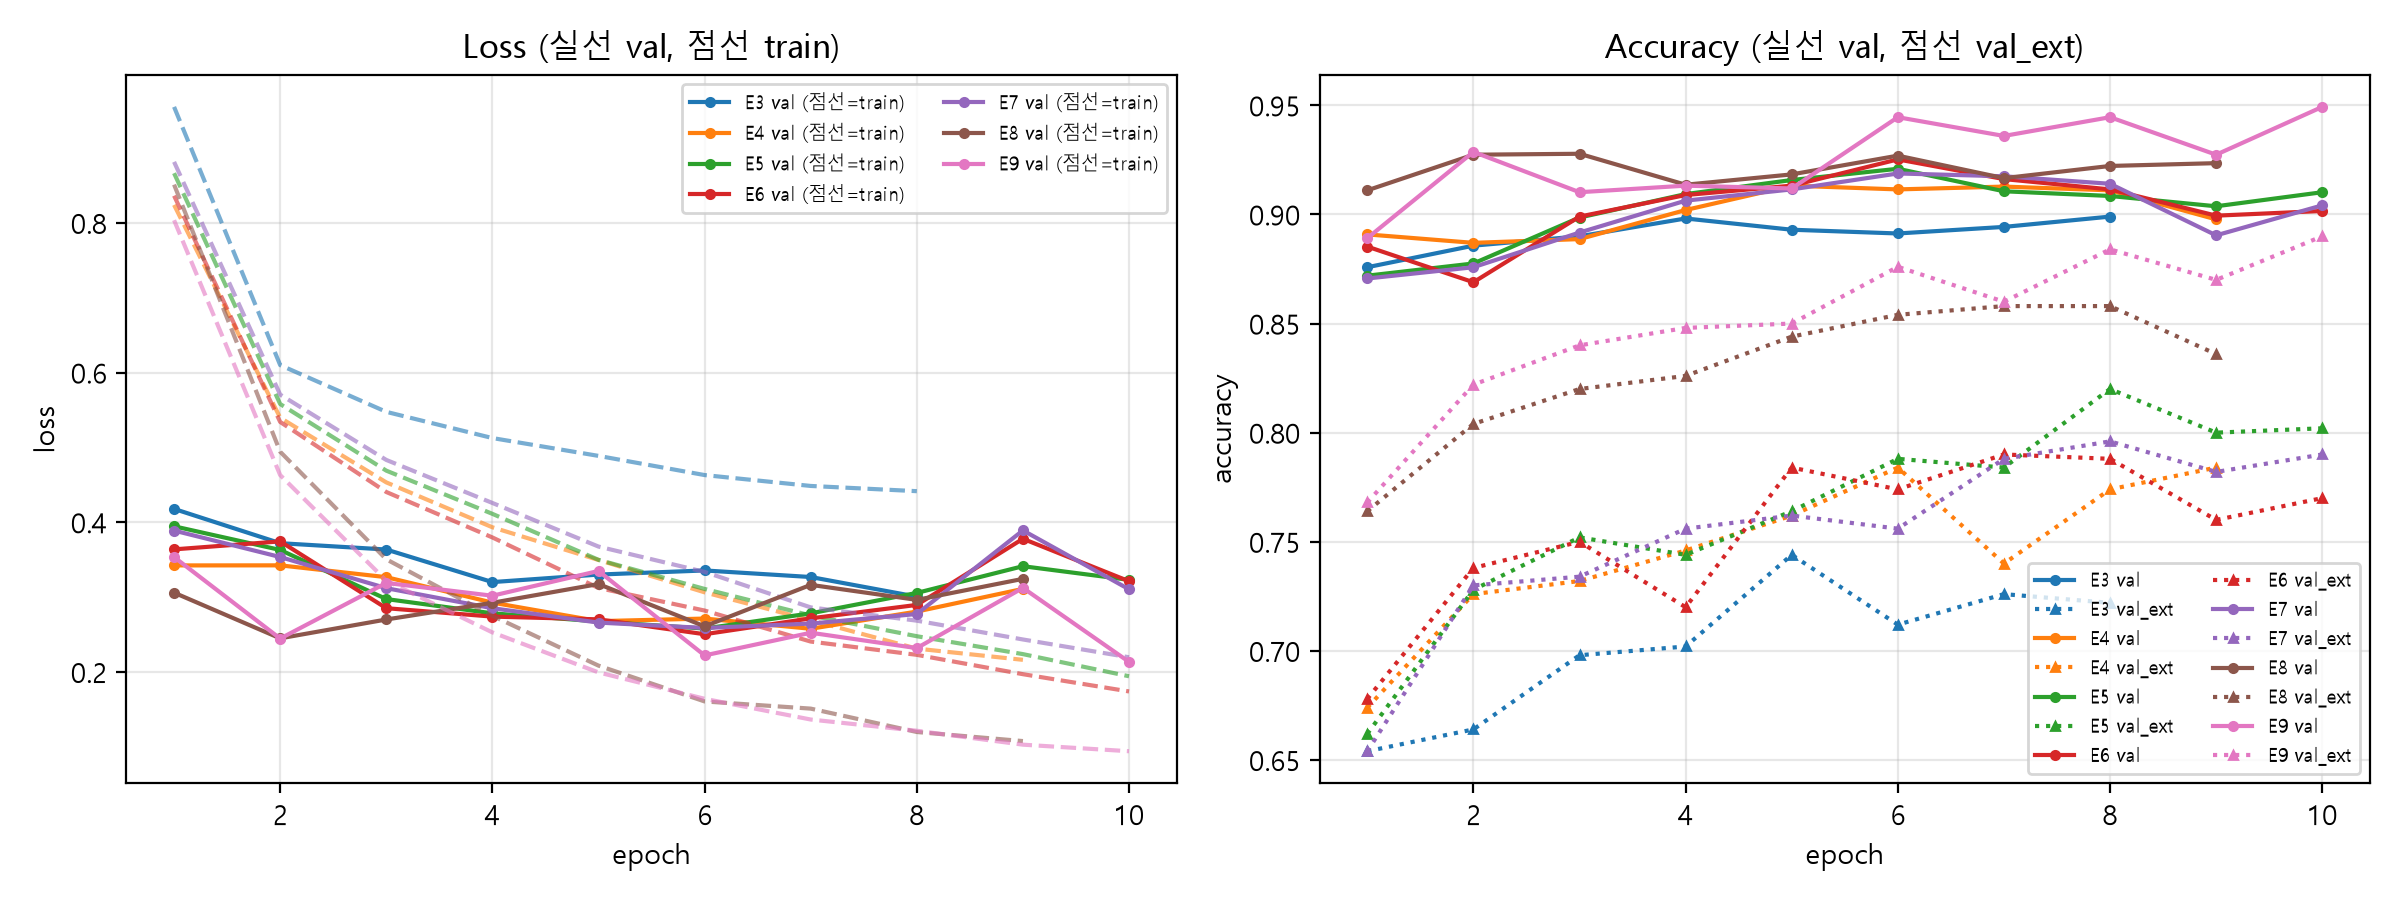

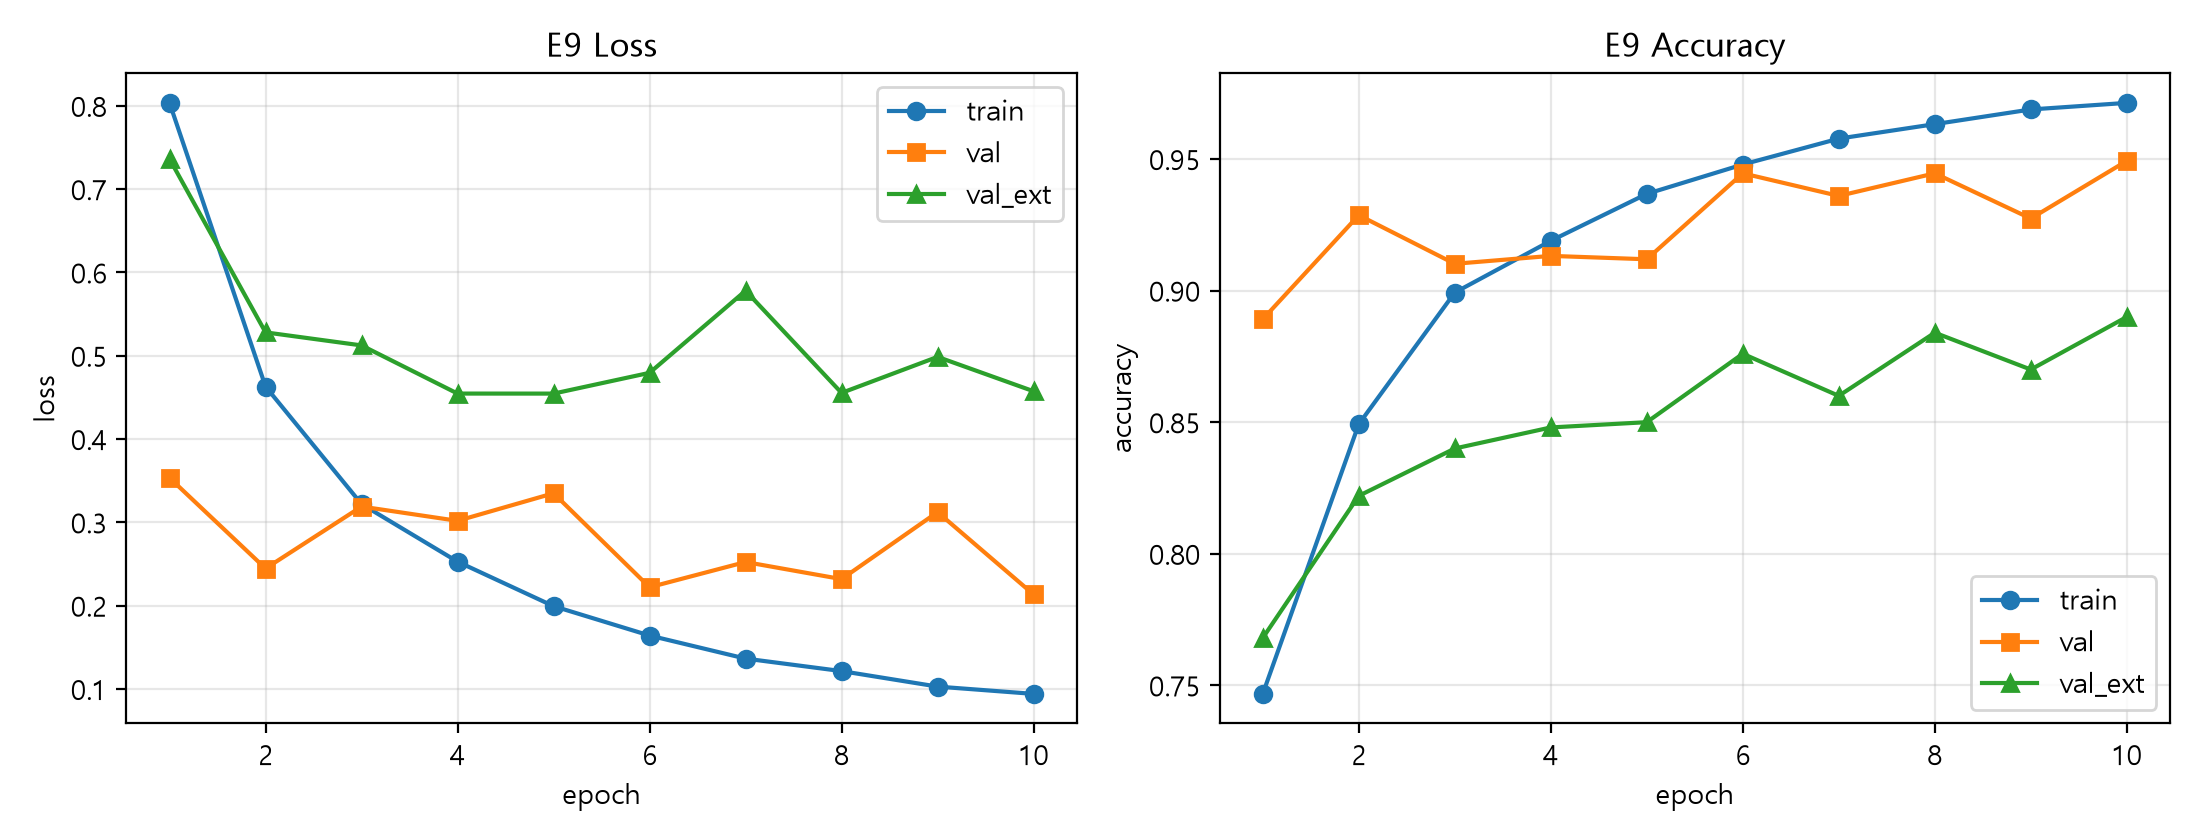

In [7]:
display(Image(filename=str(G.FIGURES / 'overnight_compare.png'), width=1000))
display(Image(filename=str(G.FIGURES / 'E9_curve.png'), width=800))

## 6. 앙상블 비교 (meta_train 1,200장으로 학습, VAL·TEST 미사용)
스태킹 채택 조건 S3 +1%p 미달 → 단일 E9 채택

In [8]:
s = json.load(open(G.RESULTS / 'stacking_results.json', encoding='utf-8'))
print('best', s.get('best'), 'partner', s.get('partner'), 'decision', s.get('decision'))
pd.DataFrame(s['results']).T

best E9 partner E8 decision single


,val,val_ext,val_hard,s3
single_E9,0.9493,0.890,0.8342,0.8912
avg_E9+E8,0.9562,0.892,0.8617,0.9033
stack_E9+E8,0.9566,0.870,0.8475,0.8914


## 7. 최종 TEST (1회): Kaggle test 2,328장 + 외부 test_ext 360장(9클래스)

In [9]:
r = json.load(open(G.RESULTS / 'final_test.json', encoding='utf-8'))
for k in ['test', 'test_ext']:
    print(k, r[k]['acc'], 'n', r[k]['n'], {s: v for s, v in r[k]['by_source'].items()})
pd.DataFrame({k: {c: v['acc'] for c, v in r[k]['by_class'].items()} for k in ['test', 'test_ext']})

test 0.9394 n 2328 {'kaggle': {'acc': 0.9394, 'n': 2328}}
test_ext 0.9083 n 360 {'aihub': {'acc': 0.9667, 'n': 180}, 'realwaste': {'acc': 0.85, 'n': 180}}


,test,test_ext
battery,0.9577,1.000
biological,0.9730,NaN
brown-glass,0.9231,0.950
cardboard,0.8881,0.825
clothes,0.9625,NaN
green-glass,0.9574,0.975
metal,0.9304,0.975
paper,0.9177,0.925
plastic,0.9077,0.775
shoes,0.9731,NaN


In [10]:
pd.read_csv(G.RESULTS / 'final_test_confusion.csv', index_col=0)

,battery,biological,brown-glass,cardboard,clothes,green-glass,metal,paper,plastic,shoes,trash,white-glass
label,,,,,,,,,,,,
battery,136,1,0,0,0,0,2,1,2,0,0,0
biological,0,144,2,1,0,0,0,0,0,0,1,0
brown-glass,0,3,84,0,0,0,2,0,1,1,0,0
cardboard,2,1,1,119,0,0,2,8,0,0,1,0
clothes,0,3,1,0,769,0,0,6,4,15,1,0
green-glass,0,0,0,2,0,90,0,0,2,0,0,0
metal,2,0,0,2,0,0,107,2,0,0,1,1
paper,2,1,0,1,0,0,3,145,2,0,4,0
plastic,0,0,0,4,0,0,2,0,118,0,5,1


## 8. 한계
- val_ext에 clothes·shoes 없음, test_ext에 biological·clothes·shoes 없음 (외부 사진 부족)
- 작은 물체·넓은 배경, 오염·찌그러짐 조건은 태그가 없어 따로 측정하지 못함 (흐림·어둡게·빛번짐만 측정)
- E9는 10 epoch 상한에서 best가 나와 추가 학습 여지가 있음